# 05 · Breakdown, sensitivities and extensions

**In the story** (notebook 00, §§4.1, 4.3, 5 and 6): this notebook examines the robustness of the 2020 verdict, where the hedging error comes from, and the boosted learner's failure in March 2020.

For §4.1, it reports robustness variant by variant. For §5, it shows that the minimum-variance correction works only on the part of the volatility move that comes with the index move. Subtracting one day's theta (sensitivity T) changes the 2020 Gains by at most 0.011. For §4.3 and §6, it documents the first appearance of a failure mode: a LightGBM correction on market features, tuned on calm 2019, broke in March 2020.

This notebook reports everything the plan declares beyond the confirmatory endpoints:

- the bucket Gains;
- the measurement variants of Table 8.1 (`analysis_plan.md` §8);
- the attribution of the hedging error;
- the exploratory challenger;
- the first SPY extension (§16.1).

None of these changes the verdict of notebook 04.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
g = pd.read_csv(R / "2020/gains.csv")
show = lambda variants: g[g.variant.isin(variants) & (g.rule == "R2") & g.base.isin(["R1", "R3", "R4"])][["variant", "cp", "base", "gain", "lo", "hi"]].round(3)
show(["primary", "A", "B", "F", "W36", "W60", "T"])

,variant,cp,base,gain,lo,hi
0,primary,C,R1,0.185,-0.357,0.463
1,primary,C,R3,0.005,-0.207,0.185
2,primary,C,R4,0.040,-0.074,0.163
9,primary,P,R1,0.120,-0.447,0.457
10,primary,P,R3,0.101,-0.112,0.303
11,primary,P,R4,0.182,-0.080,0.319
18,A,C,R1,0.147,-0.399,0.458
19,A,C,R3,0.002,-0.163,0.181
20,A,C,R4,0.037,-0.086,0.180
27,A,P,R1,0.219,-0.547,0.552


Neither the index level nor the fitting window moves the verdict.

A and B use the options' own level and the vendor's snapshot. In the pre-registered timing diagnostic (plan §8), moving from the primary to A lowers the call Gain by 0.038 (0.185 → 0.147) and raises the put Gain by 0.099 (0.120 → 0.219). Changes in opposite directions are consistent with the timing mismatch the audit found between the option quotes and the close, though they do not identify it uniquely.

W36 and W60 use the longer windows. They give the same point Gains (about 0.18 for calls and 0.14 for puts), with somewhat narrower intervals.

The frozen fit F, fitted once on 2019, does about as well as monthly refitting (calls 0.178 against 0.185; puts 0.145 against 0.120). It is the one variant in which the minimum-variance delta (R2) beats both scaling rules for puts. In 2020, refitting monthly did not help: the refits learned March too late.

Hull and White's one-day error has no intercept and no theta term. Subtracting one day's theta (the option's time decay, Lecture 6) from the option's price change in sensitivity T changes the Gains by at most 0.011 (calls 0.174 against 0.185, puts 0.112 against 0.120). The drift a hedge leaves is examined over longer horizons in notebook 10.

In [3]:
show(["P-bid", "P-ask", "P-WM", "P-SW", "S3", "V", "OTM", "OTM-refit"])

,variant,cp,base,gain,lo,hi
90,P-bid,C,R1,0.149,-0.246,0.370
91,P-bid,C,R3,0.007,-0.157,0.134
92,P-bid,C,R4,0.036,-0.045,0.119
99,P-bid,P,R1,0.101,-0.317,0.370
100,P-bid,P,R3,0.105,-0.034,0.236
101,P-bid,P,R4,0.137,-0.058,0.240
126,P-ask,C,R1,0.140,-0.247,0.392
127,P-ask,C,R3,-0.002,-0.145,0.144
128,P-ask,C,R4,0.023,-0.068,0.124
135,P-ask,P,R1,0.100,-0.357,0.414


**Marks.** Marking at the bid, the ask, the imbalance-weighted mid or Lecture 12's size-weighted price leaves the comparison where it was.

**Populations.** The spread screen (S3) lowers the point Gains, especially for puts. On the out-of-the-money subsample, Ruf and Wang's home domain, the comparison with the scaling rules stays "not distinguished". Refitting the fitted scaling (R4) on out-of-the-money pairs makes it almost exactly as good as R2 there (relative Gain about 0).

In [4]:
for col in ("delta_b", "tau_b"):
    t = pd.concat([pd.read_csv(R / f"2020/buckets_{col}_{cp}.csv") for cp in "CP"])
    print(t.round(3).to_string(index=False)); print()

cp  bucket  pairs  G_R2_R1  G_R4_R1  G_R3_R1
 C     0.1  55002    0.147    0.107    0.103
 C     0.2  41943    0.131    0.114    0.115
 C     0.3  41336    0.141    0.123    0.125
 C     0.4  44490    0.165    0.147    0.152
 C     0.5  51376    0.185    0.172    0.180
 C     0.6  54132    0.243    0.233    0.240
 C     0.7  58623    0.262    0.268    0.290
 C     0.8  63062    0.216    0.204    0.281
 C     0.9  79235    0.087   -0.152    0.026
 P     0.1 156343    0.260    0.130    0.100
 P     0.2 101945    0.255    0.168    0.127
 P     0.3  75932    0.232    0.193    0.147
 P     0.4  60691    0.177    0.187    0.150
 P     0.5  49321    0.094    0.132    0.126
 P     0.6  34981    0.042    0.045    0.089
 P     0.7  28266   -0.035   -0.168   -0.016
 P     0.8  25725   -0.130   -0.634   -0.247
 P     0.9  35052   -0.176   -2.021   -0.887

cp  bucket  pairs  G_R2_R1  G_R4_R1  G_R3_R1
 C 123-182  54014    0.162    0.113    0.159
 C   14-30 118537    0.189    0.164    0.199
 C 183-36

## Where the error comes from: the attribution

Each pair's Black–Scholes hedging error is split into vega (ν·Δσ), gamma (½Γ·ΔS²), theta, vanna, volga, carry (rate, dividend and index-timing changes) and a remainder, all divided by S_t. The table shows each term's mean square relative to the mean squared error. `xmom_*` is each term's contribution to the best scalar delta correction.

In [5]:
a = pd.read_csv(R / "2020/attribution.csv")
a[a.group.isin(["all", "stress", "rest"])][["group", "cp", "pairs", "ms_vega", "ms_gamma", "ms_theta", "ms_carry", "ms_vanna", "ms_remainder", "xmom_vega", "xmom_gamma", "xmom_carry"]].round(4)

,group,cp,pairs,ms_vega,ms_gamma,ms_theta,ms_carry,ms_vanna,ms_remainder,xmom_vega,xmom_gamma,xmom_carry
0,all,C,489144,0.5994,0.3355,0.0360,0.0743,0.0588,0.0112,-0.0413,-0.0169,-0.0070
1,all,P,566693,0.6113,0.2658,0.0312,0.0828,0.0445,0.0101,-0.0460,-0.0147,0.0090
34,stress,C,102713,0.6022,0.3723,0.0216,0.0471,0.0693,0.0123,-0.0446,-0.0172,-0.0093
35,stress,P,130732,0.6169,0.2812,0.0183,0.0808,0.0495,0.0107,-0.0499,-0.0150,0.0113
36,rest,C,386431,0.5886,0.1932,0.0915,0.1794,0.0180,0.0068,-0.0303,-0.0160,0.0007
37,rest,P,435961,0.5781,0.1740,0.1076,0.0949,0.0145,0.0064,-0.0297,-0.0134,-0.0011


**Reading.** The vega term is about 60% of the squared error, and the gamma term 27–34%. The minimum-variance delta works on the vega term: the part of the volatility move that comes with the index move.

That part is small, a delta correction of about −0.04 (`xmom_vega`). Most of the vega risk is volatility moving on its own, which no delta can hedge. That caps what any delta rule can gain.

The gamma term (the convexity of the option's value in the index, Lecture 6) is also largely beyond a delta, since it is quadratic in the index move; only a small part is reachable by a delta correction (`xmom_gamma` of about −0.015 to −0.017).

The remainder is about 1%, so the second-order expansion holds even in the stress period (24 February to 30 April 2020): a check on the Greeks.

## Other declared diagnostics

In [6]:
pd.read_csv(R / "2020/extra_diagnostics.csv")

,diagnostic,value
0,A overlap: pairs with <= 10 days left on day two,363.000000
1,"A overlap: of those, whose expiry fed day two'...",0.000000
2,C R0: SSE(WM) - SSE(SW),0.262205
3,C R0: relative to SSE(mid),0.005118
4,"C R0: n*Cov(e,u) / sum(e*u) (1 = mean product ...",0.999309
5,C R1: SSE(WM) - SSE(SW),-0.080124
6,C R1: relative to SSE(mid),-0.020451
7,"C R1: n*Cov(e,u) / sum(e*u) (1 = mean product ...",1.000804
8,P R0: SSE(WM) - SSE(SW),0.399218
9,P R0: relative to SSE(mid),0.003642


**Reading.** Under the Black–Scholes hedge (R1), the imbalance-weighted mid (WM) has about 2% less squared error than Lecture 12's size-weighted price (SW). Its changes covary negatively with the mid's hedging error, so the 16:00 size imbalance carries a little information, in the direction microstructure theory predicts.

Sensitivity A's level never reuses a hedged contract's quotes. 363 pairs had ten days or less left on day two, and none of their expiries fed that day's fallback level fit.

In [7]:
g[g.variant.isin(["day-two volume > 0", "day-two volume 0 or empty", "primary, block 5", "primary, block 20"]) & (g.rule == "R2") & g.base.isin(["R1", "R4"])][["variant", "cp", "base", "gain", "lo", "hi", "pairs"]].round(3)

,variant,cp,base,gain,lo,hi,pairs
378,day-two volume > 0,C,R1,0.188,-0.326,0.454,397518
380,day-two volume > 0,C,R4,0.054,-0.056,0.171,397518
387,day-two volume > 0,P,R1,0.119,-0.431,0.455,444732
389,day-two volume > 0,P,R4,0.193,-0.062,0.326,444732
396,day-two volume 0 or empty,C,R1,0.177,-0.473,0.487,91681
398,day-two volume 0 or empty,C,R4,0.001,-0.126,0.139,91681
405,day-two volume 0 or empty,P,R1,0.121,-0.497,0.462,123524
407,day-two volume 0 or empty,P,R4,0.148,-0.160,0.297,123524
510,"primary, block 5",C,R1,0.185,-0.356,0.453,489199
512,"primary, block 5",C,R4,0.040,-0.091,0.160,489199


In [8]:
g[(g.variant == "primary") & g.rule.isin(["R5", "R6"])][["cp", "rule", "base", "gain", "lo", "hi"]].round(3)

,cp,rule,base,gain,lo,hi
7,C,R5,R1,0.186,-0.356,0.463
8,C,R6,R1,0.164,-0.327,0.392
16,P,R5,R1,0.115,-0.453,0.453
17,P,R6,R1,-0.034,-0.555,0.305


In [9]:
print(pd.read_csv(R / "2020/mean_error_by_gap.csv").round(6).to_string(index=False))
for cp in "CP":
    print(cp, pd.read_csv(R / f"2020/ljungbox_{cp}.csv").round(4).to_string(index=False))

 gap        R0        R1        R2        R3        R4        R5        R6 variant
   1  0.000282  0.000423  0.000479  0.000464  0.000471  0.000480  0.000485       T
   3  0.001610  0.000862  0.000858  0.000900  0.000793  0.000852  0.000849       T
   4 -0.000706 -0.000186 -0.000492 -0.000375 -0.000377 -0.000491 -0.000483       T
   1  0.000015  0.000156  0.000211  0.000197  0.000203  0.000211  0.000217 primary
   3  0.001346  0.000598  0.000599  0.000635  0.000534  0.000593  0.000590 primary
   4 -0.000933 -0.000412 -0.000722 -0.000601 -0.000607 -0.000721 -0.000713 primary
C  Unnamed: 0  lb_stat  lb_pvalue cp
          5  30.9621        0.0  C
         10  55.3720        0.0  C
P  Unnamed: 0  lb_stat  lb_pvalue cp
          5  56.7213        0.0  P
         10 103.3875        0.0  P


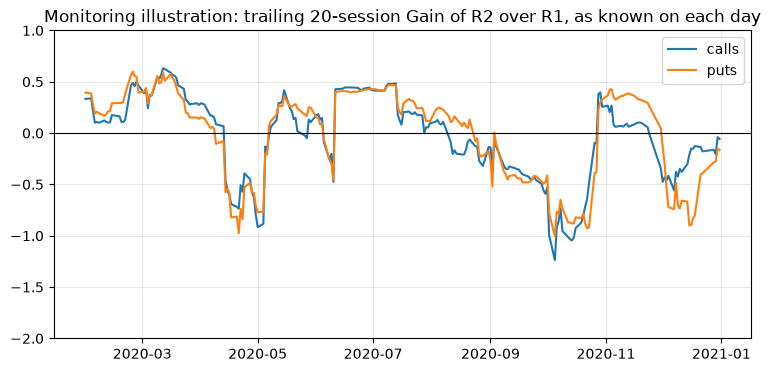

In [10]:
mon = pd.read_csv(R / "2020/monitoring.csv", parse_dates=["session"])
fig, ax = plt.subplots()
for cp in "CP":
    x = mon[mon.cp == cp]
    ax.plot(x.session, x.trailing20_gain_known, label=f"{'calls' if cp == 'C' else 'puts'}")
ax.axhline(0, color="k", lw=0.8); ax.set_ylim(-2, 1)
ax.set_title("Monitoring illustration: trailing 20-session Gain of R2 over R1, as known on each day")
ax.legend()

The monitoring illustration shows what a desk would have seen: the trailing 20-session Gain, computed only from completed hedges. It first turns negative on 9 April (puts) and 14 April (calls), about four weeks after the worst days of mid-March. It would therefore have flagged the problem only partway through April. Per the plan, no switching rule is evaluated.

## Exploratory challenger: gradient boosting (R8)

R8 is a LightGBM correction boosted from the minimum-variance delta on six market features: delta, log maturity, the option's position on its smile, the at-the-money implied volatility, 20-day realized volatility and the 5-day index return. It was tuned with Optuna on 2019 before 2020 was opened.

In [11]:
g[g.variant.str.startswith("learners") & (g.rule == "R8")][["cp", "rule", "base", "gain", "lo", "hi"]].round(3)

,cp,rule,base,gain,lo,hi
547,C,R8,R2,-0.023,-0.186,0.151
549,P,R8,R2,-9.249,-17.357,-0.185


In [12]:
pd.read_csv(R / "2020/smoothness.csv").round(4)

,rule,adjacent_pairs,out_of_order_share,mean_daily_abs_change
0,h_R1,1042891,0.0175,0.0344
1,h_R2,1042891,0.0175,0.0333
2,h_R8,1042891,0.0283,0.0493


**Reading.** The boosted correction (R8) failed badly for puts. Its Gain over R2 is −9.25: its squared error for puts was about 10 times R2's, and 9 times Black–Scholes'.

Its hyperparameters were tuned on 2019, and the trees used in March were fitted on March 2019 to February 2020. Over that window, the 20-day realized volatility never exceeded 25% and the worst 5-day index return was −12% (at the very end of February). In March 2020 those features reached 98% and −20%, far outside what the trees had seen. Their extreme leaves pushed the median put hedge ratio from −0.57 to −1.07. March's squared error for puts was 13 times R2's; in the other months it stayed within 0.8–1.6 times R2's.

The boosted correction is also rougher. It has more out-of-order hedge ratios across adjacent strikes (2.8% against 1.8%) and 48% more daily turnover than R2. R2 itself trades 3% less than Black–Scholes (a mean daily change in hedge ratio of 0.0333 against 0.0344), so the correction would not raise proportional trading costs.

That is the failure mode the non-smooth-hedge argument predicts: a flexible learner extrapolates arbitrarily outside its training data. Notebook 08 shows that the features, not the boosting, broke it: a LightGBM correction on delta alone stayed with R2 throughout 2020.

## SPY (§16.1)

*Superseded on 2026-11-05 by the full replication of plan §16.3: see notebook 07. The numbers below are the 2026-11-04 exploratory run, kept as the record.*

The same protocol is applied to SPY: American options (Lecture 12's tree for puts), SPY's own close, and distributions added to the hedge leg on ex-dates.

In [13]:
s = pd.read_csv(R / "spy/gains.csv")
s[(s.rule == "R2") & s.base.isin(["R1", "R3", "R4"])][["variant", "cp", "base", "gain", "lo", "hi", "pairs"]].round(3)

,variant,cp,base,gain,lo,hi,pairs
0,primary,C,R1,0.104,-0.298,0.398,521009
1,primary,C,R3,0.057,-0.030,0.185,521009
2,primary,C,R4,0.046,-0.094,0.212,521009
8,primary,P,R1,0.238,-0.249,0.477,509748
9,primary,P,R3,0.052,-0.194,0.205,509748
10,primary,P,R4,0.055,-0.105,0.157,509748
16,ex-date pairs only,C,R1,-0.573,NaN,NaN,6122
17,ex-date pairs only,P,R1,-0.687,NaN,NaN,6547
18,B,C,R1,0.122,-0.331,0.394,521009
19,B,C,R3,0.051,-0.022,0.155,521009


**Reading.** SPY tells the same story. The point Gains are positive (0.10 for calls, 0.24 for puts), the intervals span zero, and the scaling rules are not distinguished.

The ex-date-only rows are too thin to interpret. 2020 has three ex-dates with pairs, so some bootstrap draws (about 4%) contain none, and any such draw leaves the interval undefined.

On ex-date pairs, adding the distribution to the hedge leg helps puts but not calls. That is the limitation stated in advance: calls are priced as European. A deep in-the-money American call carries an early-exercise premium before the ex-date, which vanishes on it.